## Part B: the myCobot 320 arm responds to optical density

**Objectives 4 and 5.** Connect to the arm, run a predefined test movement, then make the arm move when the
live optical density (OD) of the culture crosses a threshold.

**Runs anywhere.** If no arm is connected (in Colab, or on a judge's laptop) the notebook switches to
**dry-run mode**: it prints every command it would send and draws the arm's pose, so every step can still be
checked. On the laptop that is plugged into the arm, the same cells drive the real robot.

In [1]:
import importlib.util, subprocess, sys, os, glob, time, math
from datetime import datetime, timezone
from pathlib import Path

if importlib.util.find_spec("pymycobot") is None:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pymycobot"], check=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROBOTICS_DIR = Path(".") if Path("PLAN.md").exists() else Path("robotics") if Path("robotics/PLAN.md").exists() else Path(".")
EVIDENCE = ROBOTICS_DIR / "evidence" / "arm"
EVIDENCE.mkdir(parents=True, exist_ok=True)

# Where the arm is. Leave as None to auto-detect; set ARM_PORT (USB, "M5" version) or ARM_IP (WiFi, "Pi" version).
ARM_PORT = os.environ.get("ARM_PORT")          # e.g. "/dev/tty.usbserial-0001" (Mac) or "COM3" (Windows)
ARM_IP = os.environ.get("ARM_IP")              # e.g. "192.168.1.42": on the arm's Pi run Server_320.py first
# Server_320.py (official, Elephant Robotics): https://raw.githubusercontent.com/elephantrobotics/pymycobot/main/demo/Server_320.py
# It listens on the Pi's WiFi address, port 9000. Or run this notebook ON the arm's Pi: it then uses /dev/ttyAMA0.
SPEED = 30                                     # percent of max speed: slow and safe

### Connect: real arm if we can find one, otherwise dry-run
The myCobot 320 comes in two versions. The **M5** version plugs into the laptop by USB (a serial port).
The **Pi** version has its own small computer and is reached over the network (port 9000).
We try both, and fall back to a stand-in "dry-run" arm with the same commands.

In [2]:
class DryRunArm:
    """Same commands as the real arm; records poses instead of moving motors."""
    name = "dry-run (no arm connected)"

    def __init__(self):
        self.angles = [0.0] * 6
        self.history = []

    def power_on(self):
        print("[dry-run] power_on")

    def send_angles(self, angles, speed, _async=False):
        print(f"[dry-run] send_angles({[round(a, 1) for a in angles]}, speed={speed})")
        self.angles = list(map(float, angles))
        self.history.append(list(self.angles))

    def get_angles(self):
        return list(self.angles)

    def is_moving(self):
        return 0

    def release_all_servos(self):
        print("[dry-run] release_all_servos")


def candidate_ports():
    pats = ["/dev/tty.usbserial*", "/dev/tty.SLAB_USBtoUART*", "/dev/tty.wchusbserial*",
            "/dev/cu.usbserial*", "/dev/ttyUSB*", "/dev/ttyACM*"]
    return sorted({p for pat in pats for p in glob.glob(pat)})


def connect_arm():
    from pymycobot import MyCobot320, MyCobot320Socket
    tries = []
    # Running ON the arm's own Raspberry Pi (myCobot 320 Pi): the motors are on /dev/ttyAMA0 at 115200 baud.
    if not ARM_PORT and not ARM_IP and os.path.exists("/dev/ttyAMA0"):
        for baud in (115200, 1000000):
            try:
                arm = MyCobot320("/dev/ttyAMA0", baud)
                arm.power_on()
                time.sleep(0.5)
                if arm.get_angles():
                    arm.name = f"myCobot 320 Pi (on-board, /dev/ttyAMA0 @ {baud})"
                    return arm
                tries.append(f"/dev/ttyAMA0 @ {baud}: no answer")
            except Exception as e:
                tries.append(f"/dev/ttyAMA0 @ {baud}: {e}")
    for port in ([ARM_PORT] if ARM_PORT else candidate_ports()):
        try:
            arm = MyCobot320(port, 115200)
            arm.power_on()
            time.sleep(0.5)
            if arm.get_angles():                       # the arm answered
                arm.name = f"myCobot 320 M5 on {port}"
                return arm
            tries.append(f"{port}: no answer")
        except Exception as e:
            tries.append(f"{port}: {e}")
    if ARM_IP:
        try:
            arm = MyCobot320Socket(ARM_IP, 9000)
            arm.power_on()
            time.sleep(0.5)
            if arm.get_angles():
                arm.name = f"myCobot 320 Pi at {ARM_IP}"
                return arm
            tries.append(f"{ARM_IP}: no answer")
        except Exception as e:
            tries.append(f"{ARM_IP}: {e}")
    for t in tries:
        print("  tried", t)
    return DryRunArm()


arm = connect_arm()
print("Arm:", arm.name)

Arm: dry-run (no arm connected)


### Objective 4: a predefined test movement
Small joint moves at low speed, waiting for each move to finish before the next. **Every move is relative to
the pose the arm is already in** (no big swing to an absolute "zero" pose): turn the base left → right,
lift and lower the wrist, then return to the starting pose. Every pose is checked by reading the angles back.

starting pose: [0.0, 0.0, 0.0, 0.0, 0.0, 0.0]
[dry-run] send_angles([0.0, 0.0, 0.0, 0.0, 0.0, 0.0], speed=30)


[dry-run] send_angles([20.0, 0.0, 0.0, 0.0, 0.0, 0.0], speed=30)


[dry-run] send_angles([-20.0, 0.0, 0.0, 0.0, 0.0, 0.0], speed=30)


[dry-run] send_angles([0.0, 0.0, 0.0, 20.0, 0.0, 0.0], speed=30)


[dry-run] send_angles([0.0, 0.0, 0.0, -20.0, 0.0, 0.0], speed=30)


[dry-run] send_angles([0.0, 0.0, 0.0, 0.0, 0.0, 0.0], speed=30)


,step,target,reached
0,start,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0]","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0]"
1,base left,"[20.0, 0.0, 0.0, 0.0, 0.0, 0.0]","[20.0, 0.0, 0.0, 0.0, 0.0, 0.0]"
2,base right,"[-20.0, 0.0, 0.0, 0.0, 0.0, 0.0]","[-20.0, 0.0, 0.0, 0.0, 0.0, 0.0]"
3,wrist up,"[0.0, 0.0, 0.0, 20.0, 0.0, 0.0]","[0.0, 0.0, 0.0, 20.0, 0.0, 0.0]"
4,wrist down,"[0.0, 0.0, 0.0, -20.0, 0.0, 0.0]","[0.0, 0.0, 0.0, -20.0, 0.0, 0.0]"
5,start,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0]","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0]"


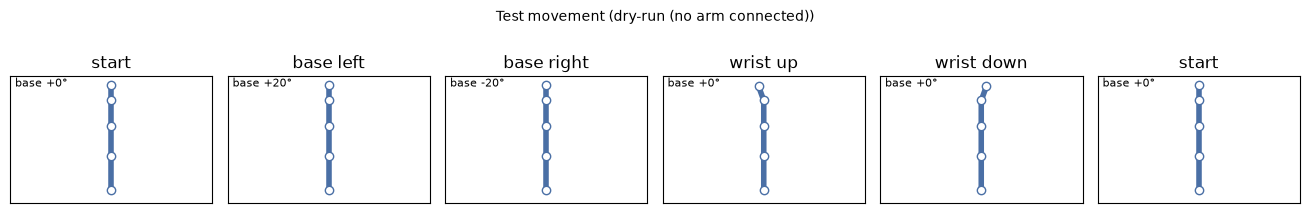

In [3]:
STEP = 20                                              # degrees per nudge: small and safe
HOME = [round(a, 1) for a in (arm.get_angles() or [0.0] * 6)]   # where the arm is right now
print("starting pose:", HOME)


def nudge(joint, delta):
    pose = list(HOME)
    pose[joint] += delta
    return pose


TEST_MOVES = [
    ("start", HOME),
    ("base left", nudge(0, +STEP)),
    ("base right", nudge(0, -STEP)),
    ("wrist up", nudge(3, +STEP)),
    ("wrist down", nudge(3, -STEP)),
    ("start", HOME),
]


def move(arm, angles, speed=SPEED, timeout=15.0):
    """Send a pose and wait until the arm stops (or the timeout passes). Returns the angles read back."""
    arm.send_angles(angles, speed)
    t0 = time.time()
    time.sleep(0.3)
    while time.time() - t0 < timeout:
        try:
            if not arm.is_moving():
                break
        except Exception:
            pass
        time.sleep(0.2)
    return arm.get_angles()


def draw_pose(ax, angles, title=""):
    """Side view of a simplified arm (joints 2, 3, 4 bend in the vertical plane) plus base rotation as text."""
    links = [0.135, 0.12, 0.10, 0.06]                     # approximate link lengths (m)
    x, y, a = [0.0], [0.0], math.pi / 2
    for L, j in zip(links, [0, angles[1], angles[2], angles[3]]):
        a += math.radians(j)
        x.append(x[-1] + L * math.cos(a)); y.append(y[-1] + L * math.sin(a))
    ax.plot(x, y, "-o", lw=4, color="#4a6fa5", mfc="white")
    ax.set(xlim=(-0.4, 0.4), ylim=(-0.05, 0.45), aspect="equal", title=title)
    ax.text(-0.38, 0.41, f"base {angles[0]:+.0f}°", fontsize=8)
    ax.set_xticks([]); ax.set_yticks([])


test_log = []
for label, pose in TEST_MOVES:
    reached = move(arm, pose)
    test_log.append(dict(step=label, target=pose, reached=[round(a, 1) for a in reached]))
display(pd.DataFrame(test_log))

fig, axes = plt.subplots(1, len(TEST_MOVES), figsize=(2.2 * len(TEST_MOVES), 2.4))
for ax, (label, pose) in zip(axes, TEST_MOVES):
    draw_pose(ax, pose, label)
plt.suptitle(f"Test movement ({arm.name})", fontsize=10); plt.tight_layout(); plt.show()

### Objective 5: respond to an OD reading

**The rule.** When the OD rises **above the threshold**, the arm performs one response movement (a "nod").
It then **re-arms only after OD falls back below `threshold − margin`**. This *hysteresis* means noise around
the threshold can't make the arm fire over and over: **one crossing gives exactly one movement**, every time.
That makes the response repeatable, which is the tie-breaker in scoring.

**OD source.** The live reading comes from `latest_od()` in Part A (Pioreactor API). If Part A isn't loaded
or the API is down, a recorded or simulated OD series is used instead, and the notebook says which.

In [4]:
class ThresholdTrigger:
    def __init__(self, threshold, margin):
        self.threshold, self.margin, self.armed = threshold, margin, True

    def update(self, od):
        """Return True exactly once per upward crossing of the threshold."""
        if self.armed and od > self.threshold:
            self.armed = False
            return True
        if not self.armed and od < self.threshold - self.margin:
            self.armed = True
        return False


# Self-check: noisy OD that crosses the threshold twice must fire exactly twice.
rng = np.random.default_rng(0)
test_series = np.concatenate([np.linspace(0.10, 0.30, 40), np.linspace(0.30, 0.10, 40)] * 2) + rng.normal(0, 0.01, 160)
trig = ThresholdTrigger(0.20, 0.03)
fires = [i for i, v in enumerate(test_series) if trig.update(v)]
assert len(fires) == 2, fires
print(f"self-check passed: 2 crossings in noisy data → {len(fires)} triggers (at samples {fires})")

RESPONSE = [("nod down", nudge(3, -STEP)), ("nod up", nudge(3, +STEP)), ("back to start", HOME)]


def respond(arm):
    for _, pose in RESPONSE:
        move(arm, pose)
    return arm.get_angles()

self-check passed: 2 crossings in noisy data → 2 triggers (at samples [19, 100])


OD source: simulated OD (Part A not connected: live API unavailable)
threshold 0.2, re-arm below 0.1700
[dry-run] send_angles([0.0, 0.0, 0.0, -20.0, 0.0, 0.0], speed=30)


[dry-run] send_angles([0.0, 0.0, 0.0, 20.0, 0.0, 0.0], speed=30)


[dry-run] send_angles([0.0, 0.0, 0.0, 0.0, 0.0, 0.0], speed=30)


2026-11-07T19:54:28+00:00  OD 0.2143 > 0.2  →  arm responded
[dry-run] send_angles([0.0, 0.0, 0.0, -20.0, 0.0, 0.0], speed=30)


[dry-run] send_angles([0.0, 0.0, 0.0, 20.0, 0.0, 0.0], speed=30)


[dry-run] send_angles([0.0, 0.0, 0.0, 0.0, 0.0, 0.0], speed=30)


2026-11-07T19:54:28+00:00  OD 0.2143 > 0.2  →  arm responded


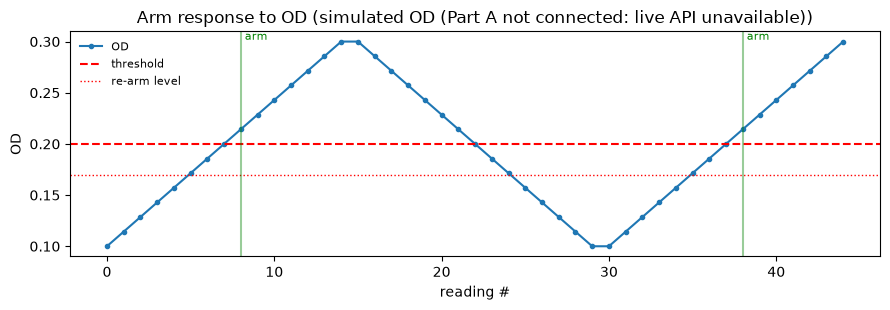

2 responses from 45 readings; log saved to evidence/arm/trigger_log.csv


In [5]:
def simulated_od():
    """Fallback OD: rises past the threshold, falls back, and rises again (two crossings)."""
    for v in np.concatenate([np.linspace(0.10, 0.30, 15), np.linspace(0.30, 0.10, 15), np.linspace(0.10, 0.30, 15)]):
        yield datetime.now(timezone.utc).isoformat(timespec="seconds"), float(v)


live = "latest_od" in globals() and globals().get("EXPERIMENT")
if live:
    first = latest_od(EXPERIMENT)
    live = first is not None
if live:
    SOURCE = f"live Pioreactor OD (experiment {EXPERIMENT})"
    THRESHOLD = round(first[1] + 0.02, 4)      # just above the current reading, so growth (or a nudge) crosses it
    MARGIN = 0.01
    POLLS, EVERY = 60, 5.0                     # 5 minutes of polling every 5 s
    def readings():
        for _ in range(POLLS):
            r = latest_od(EXPERIMENT)
            if r:
                yield r
            time.sleep(EVERY)
else:
    SOURCE = "simulated OD (Part A not connected: live API unavailable)"
    THRESHOLD, MARGIN = 0.20, 0.03
    readings = simulated_od
print(f"OD source: {SOURCE}\nthreshold {THRESHOLD}, re-arm below {THRESHOLD - MARGIN:.4f}")

trigger = ThresholdTrigger(THRESHOLD, MARGIN)
log = []
for ts, od in readings():
    fired = trigger.update(od)
    pose = respond(arm) if fired else None
    log.append(dict(time=ts, od=od, threshold=THRESHOLD, event="ARM MOVED" if fired else "",
                    pose=[round(a, 1) for a in pose] if pose else ""))
    if fired:
        print(f"{ts}  OD {od:.4f} > {THRESHOLD}  →  arm responded")
log = pd.DataFrame(log)
log.to_csv(EVIDENCE / "trigger_log.csv", index=False)

fig, ax = plt.subplots(figsize=(9, 3.2))
ax.plot(range(len(log)), log.od, "-o", ms=3, label="OD")
ax.axhline(THRESHOLD, color="r", ls="--", label="threshold")
ax.axhline(THRESHOLD - MARGIN, color="r", ls=":", lw=1, label="re-arm level")
for i in log.index[log.event != ""]:
    ax.axvline(i, color="green", alpha=0.4); ax.text(i, ax.get_ylim()[1], " arm", color="green", fontsize=8, va="top")
ax.set(xlabel="reading #", ylabel="OD", title=f"Arm response to OD ({SOURCE})"); ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()
print(f"{(log.event != '').sum()} responses from {len(log)} readings; log saved to {EVIDENCE / 'trigger_log.csv'}")